<a href="https://colab.research.google.com/github/EgorMehed/ML-homework/blob/main/%D0%9B%D0%A0_2_3_%D0%9C%D0%B5%D1%85%D0%B5%D0%B4_%D0%84%D0%B3%D0%BE%D1%80_%D0%A4%D0%86%D0%A2_3_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Імпорт бібліотек та завантаження даних

In [1]:
import pandas as pd
import urllib.request
import urllib.parse
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://uk.wikipedia.org/wiki/" + urllib.parse.quote("Населення_України")

req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
html_content = urllib.request.urlopen(req).read().decode('utf-8')

df = pd.read_html(html_content, match="Коефіцієнт народжуваності")[0]

/tmp/ipykernel_4636/867685975.py:15: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  df = pd.read_html(html_content, match="Коефіцієнт народжуваності")[0]


Огляд даних

In [2]:
df.head()

,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,230.0,206.0,160.0,130,73,126,—,—
1,Вінницька,224.0,192.0,142.0,124,84,112,109,76
2,Волинська,247.0,250.0,179.0,153,112,148,141,101
3,Дніпропетровська,204.0,204.0,151.0,123,71,112,111,71
4,Донецька,271.0,214.0,140.0,109,61,98,82,—


In [3]:
df.describe()

,1950,1960,1970,1990,2000,2012
count,26.000000,27.000000,27.000000,28.000000,28.000000,28.000000
mean,230.923077,207.481481,155.851852,130.428571,82.071429,116.464286
std,28.220451,29.360322,18.703565,15.278716,15.568079,16.362745
min,186.000000,163.000000,127.000000,108.000000,61.000000,94.000000
25%,211.500000,186.500000,144.000000,122.250000,70.750000,104.500000
50%,226.000000,204.000000,152.000000,126.000000,78.500000,114.500000
75%,246.000000,220.500000,163.000000,140.500000,89.500000,122.500000
max,314.000000,273.000000,207.000000,168.000000,118.000000,159.000000


Очищення

In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df.dtypes

,0
Регіон,object
1950,float64
1960,float64
1970,float64
1990,int64
2000,int64
2012,int64
2014,object
2019,object


In [6]:
for col in df.columns[1:]:
    df[col] = df[col].astype(str).str.replace(',', '.')
    df[col] = pd.to_numeric(df[col], errors='coerce')

df.dtypes

,0
Регіон,object
1950,float64
1960,float64
1970,float64
1990,int64
2000,int64
2012,int64
2014,float64
2019,float64


In [8]:
df.isna().sum()

,0
Регіон,0
1950,2
1960,1
1970,1
1990,0
2000,0
2012,0
2014,2
2019,4


In [9]:
df_indexed = df.set_index('Регіон')
df_indexed = df_indexed.interpolate(method='linear', axis=1, limit_direction='both')

df_indexed.isnull().sum()

,0
1950,0
1960,0
1970,0
1990,0
2000,0
2012,0
2014,0
2019,0


In [10]:
df_indexed.describe()

,1950,1960,1970,1990,2000,2012,2014,2019
count,28.000000,28.000000,28.000000,28.000000,28.000000,28.000000,28.000000,28.000000
mean,225.107143,204.535714,154.750000,130.428571,82.071429,116.464286,112.250000,82.285714
std,35.183476,32.757789,19.257755,15.278716,15.568079,16.362745,19.610324,18.512973
min,125.000000,125.000000,125.000000,108.000000,61.000000,94.000000,51.000000,51.000000
25%,207.250000,183.750000,143.500000,122.250000,70.750000,104.500000,104.750000,68.000000
50%,222.000000,201.000000,151.500000,126.000000,78.500000,114.500000,112.000000,79.500000
75%,244.000000,219.250000,161.500000,140.500000,89.500000,122.500000,121.250000,89.000000
max,314.000000,273.000000,207.000000,168.000000,118.000000,159.000000,148.000000,126.000000


In [11]:
df_indexed = df_indexed / 10

df_indexed.describe()

,1950,1960,1970,1990,2000,2012,2014,2019
count,28.000000,28.000000,28.000000,28.000000,28.000000,28.000000,28.000000,28.000000
mean,22.510714,20.453571,15.475000,13.042857,8.207143,11.646429,11.225000,8.228571
std,3.518348,3.275779,1.925775,1.527872,1.556808,1.636274,1.961032,1.851297
min,12.500000,12.500000,12.500000,10.800000,6.100000,9.400000,5.100000,5.100000
25%,20.725000,18.375000,14.350000,12.225000,7.075000,10.450000,10.475000,6.800000
50%,22.200000,20.100000,15.150000,12.600000,7.850000,11.450000,11.200000,7.950000
75%,24.400000,21.925000,16.150000,14.050000,8.950000,12.250000,12.125000,8.900000
max,31.400000,27.300000,20.700000,16.800000,11.800000,15.900000,14.800000,12.600000


1. Глибина демографічного спаду (1950 проти 2019 рр.): У яких регіонах України відбулося найбільше абсолютне падіння коефіцієнта народжуваності за весь період спостережень?

2. Динаміка відновлення після кризи 2000 року (2000 проти 2012 рр.): Які області продемонстрували найстрімкіше зростання народжуваності в період від «демографічного дна» (2000 р.) до локального піку (2012 р.)?

3. Відхилення від середньоукраїнського рівня (2019 рік): Які регіони у 2019 році мали показники вищі за загальнонаціональний рівень, а які суттєво відставали?

4. Еволюція варіативності та медіани (1950–2019 рр.): Як змінювалися розкид значень, міжквартильний розмах та медіанний рівень народжуваності між областями в кожен із досліджуваних років (Boxplot)?

5. Траєкторії контрастних регіонів: Як відрізнялася багаторічна динаміка народжуваності столиці (Київ) порівняно з лідерами (Рівненська, Закарпатська) та промисловим сходом (Донецька, Луганська)?

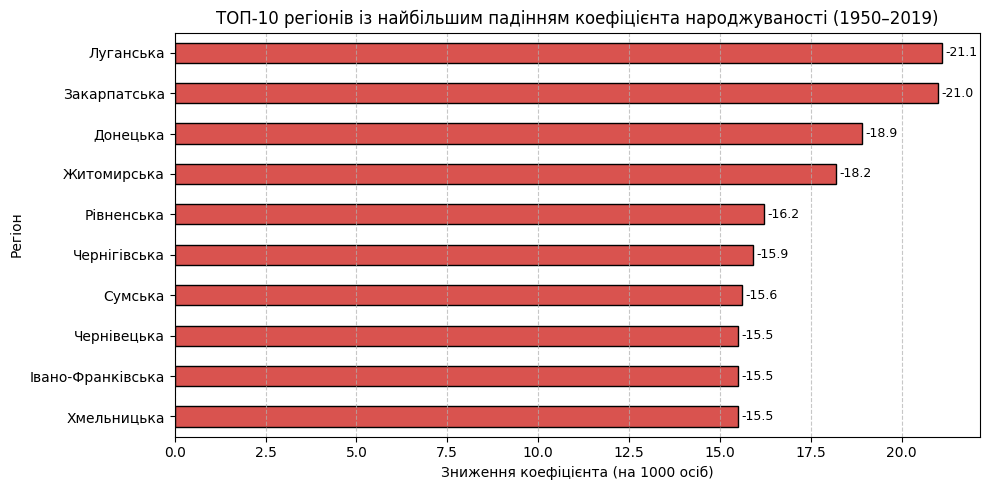

In [12]:
# 1. ТОП-10 регіонів із найбільшим спадом народжуваності (1950–2019 рр.)
df_reg = df_indexed.drop(index=['Україна'], errors='ignore')
drop_series = (df_reg['1950'] - df_reg['2019']).sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
drop_series.sort_values(ascending=True).plot(kind='barh', color='#d9534f', edgecolor='black')
plt.title("ТОП-10 регіонів із найбільшим падінням коефіцієнта народжуваності (1950–2019)")
plt.xlabel("Зниження коефіцієнта (на 1000 осіб)")
plt.ylabel("Регіон")
plt.grid(axis='x', linestyle='--', alpha=0.7)

for index, value in enumerate(drop_series.sort_values(ascending=True)):
    plt.text(value + 0.1, index, f"-{value:.1f}", va='center', fontsize=9)

plt.tight_layout()
plt.savefig("chart1.png")
plt.show()

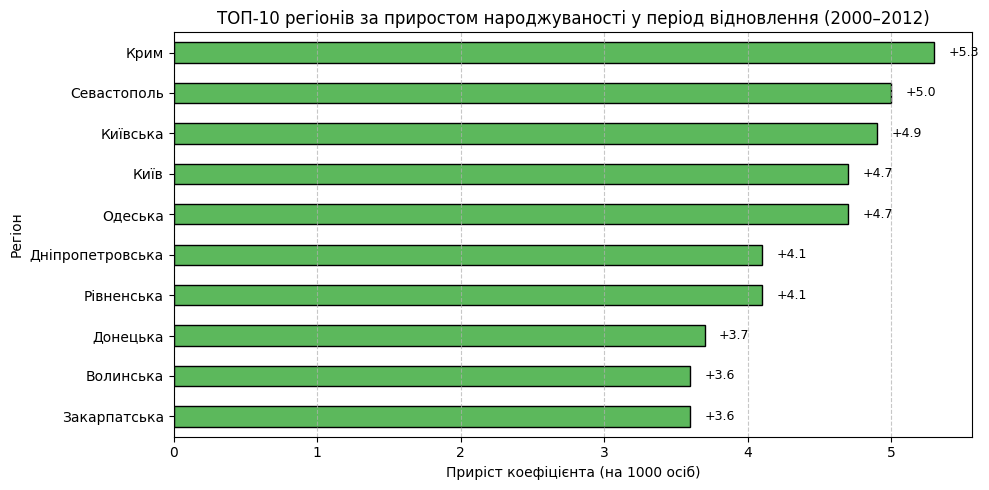

In [13]:
# 2. Регіони з найсильнішим відновленням народжуваності (2000–2012 рр.)
growth_series = (df_reg['2012'] - df_reg['2000']).sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
growth_series.sort_values(ascending=True).plot(kind='barh', color='#5cb85c', edgecolor='black')
plt.title("ТОП-10 регіонів за приростом народжуваності у період відновлення (2000–2012)")
plt.xlabel("Приріст коефіцієнта (на 1000 осіб)")
plt.ylabel("Регіон")
plt.grid(axis='x', linestyle='--', alpha=0.7)

for index, value in enumerate(growth_series.sort_values(ascending=True)):
    plt.text(value + 0.1, index, f"+{value:.1f}", va='center', fontsize=9)

plt.tight_layout()
plt.savefig("chart2.png")
plt.show()

In [ ]:
# 3. Відхилення від середнього рівня по Україні у 2019 році
ukr_mean = df_indexed.loc['Україна', '2019'] if 'Україна' in df_indexed.index else df_reg['2019'].mean()
diff_2019 = (df_reg['2019'] - ukr_mean).sort_values()

colors = ['#d9534f' if x < 0 else '#5cb85c' for x in diff_2019]

plt.figure(figsize=(10, 8))
plt.barh(diff_2019.index, diff_2019.values, color=colors, edgecolor='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=1.2, linestyle='--')
plt.title(f"Відхилення коефіцієнта народжуваності регіонів від рівня України у 2019 р. ({ukr_mean:.1f})")
plt.xlabel("Відхилення від рівня України (на 1000 осіб)")
plt.ylabel("Регіон")
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig("chart3.png")
plt.show()

In [ ]:
# 4. Еволюція розподілу та варіативності народжуваності за роками (Boxplot)
plt.figure(figsize=(11, 6))
sns.boxplot(data=df_reg, palette="Blues", showmeans=True,
            meanprops={"marker":"o", "markerfacecolor":"red", "markeredgecolor":"red", "markersize":"5"})
plt.title("Еволюція розподілу та варіативності народжуваності в регіонах України (1950–2019)")
plt.xlabel("Рік")
plt.ylabel("Коефіцієнт народжуваності (на 1000 осіб)")
plt.plot([], [], marker='o', color='red', linestyle='None', label='Середнє значення')
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig("chart4.png")
plt.show()

In [ ]:
# 5. Порівняння багаторічних траєкторій для контрастних регіонів
contrast_regions = ['Київ', 'Рівненська', 'Закарпатська', 'Донецька', 'Луганська']
available_regions = [r for r in contrast_regions if r in df_indexed.index]

plt.figure(figsize=(11, 6))
years = df_indexed.columns

for region in available_regions:
    plt.plot(years, df_indexed.loc[region], marker='o', linewidth=2.2, label=region)

if 'Україна' in df_indexed.index:
    plt.plot(years, df_indexed.loc['Україна'], color='black', linestyle='--', linewidth=2, label='Україна (середнє)')

plt.title("Динаміка народжуваності в контрастних регіонах України (1950–2019)")
plt.xlabel("Рік")
plt.ylabel("Коефіцієнт народжуваності (на 1000 осіб)")
plt.legend(title="Регіон", loc='upper right')
plt.grid(True, linestyle=':')

plt.tight_layout()
plt.savefig("chart5.png")
plt.show()